# 02. Why does missing BMI carry about 4× the stroke rate? (action items D1 to D4)

Professor point F4 asks why patients with missing BMI have about four times the stroke rate, and whether filling in the values can recover what is going on. Background: `knowledge_base/04_missing_data_mechanisms.md`.

**Status of these analyses.** They are exploratory investigations of a pattern already seen in the proposal, so they are not pre-registered hypotheses and are not part of the Holm-corrected family. Every test is recorded in `results/test_log.md`.

**How to read the intervals.** A 95% interval comes from a procedure that would capture the true value in about 95% of repeated samples. The data are consistent with values in the interval. It is not a 95% probability statement about this particular interval.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

from src.config import ALPHA, FIGURES, N_BOOT, N_IMPUTATIONS, SEED, TABLES
from src.data import load_raw

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
RECORDED, MISSING = "#2a78d6", "#eb6834"  # colour follows the group in every figure
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

df = load_raw()
df["bmi_missing"] = df["bmi"].isna().astype(int)

import warnings

import patsy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.optimize import brentq
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(SEED)
m, r = df[df["bmi_missing"] == 1], df[df["bmi_missing"] == 0]
print(f"BMI missing: {len(m)} patients, BMI recorded: {len(r)} patients")

BMI missing: 201 patients, BMI recorded: 4909 patients


## D1. How do the missing-BMI and recorded-BMI groups differ?

Differences are BMI missing minus BMI recorded. Mean differences use a percentile bootstrap that resamples within each group (`N_BOOT` resamples), because age and glucose are not Normal. Welch p-values are shown beside them. Differences in percentages use Newcombe intervals.

For the χ² test on work type, `children` and `Never_worked` are combined, because `Never_worked` has an expected count below 1 in the missing-BMI group and no missing-BMI patients at all. The category-level table above the test keeps all five work types.

In [2]:
def boot_mean_diff(x1, x0, B=N_BOOT):
    """Percentile bootstrap CI for mean(x1) - mean(x0), resampling within each group."""
    d = np.array([x1[rng.integers(0, len(x1), len(x1))].mean()
                  - x0[rng.integers(0, len(x0), len(x0))].mean() for _ in range(B)])
    return np.quantile(d, [ALPHA / 2, 1 - ALPHA / 2])

rows = []
for col, label in [("age", "Age, years"), ("avg_glucose_level", "Glucose, mg/dL")]:
    x1, x0 = m[col].to_numpy(), r[col].to_numpy()
    lo, hi = boot_mean_diff(x1, x0)
    sd = np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    rows.append({"variable": label, "missing_mean": x1.mean(), "recorded_mean": x0.mean(),
                 "difference": x1.mean() - x0.mean(), "ci_low": lo, "ci_high": hi,
                 "smd": (x1.mean() - x0.mean()) / sd,
                 "welch_p": stats.ttest_ind(x1, x0, equal_var=False).pvalue})
cont = pd.DataFrame(rows)
cont.to_csv(TABLES / "missing_bmi_continuous_comparison.csv", index=False)
display(cont.round(4))

,variable,missing_mean,recorded_mean,difference,ci_low,ci_high,smd,welch_p
0,"Age, years",52.0492,42.8654,9.1838,5.9817,12.3349,0.4097,0.0
1,"Glucose, mg/dL",126.7246,105.3051,21.4195,13.4580,29.9769,0.4091,0.0


In [3]:
df["work_group"] = df["work_type"].astype(str).replace(
    {"children": "Child_or_never_worked", "Never_worked": "Child_or_never_worked"})

def binary_row(label, mask):
    k1, n1 = int(mask[df["bmi_missing"] == 1].sum()), len(m)
    k0, n0 = int(mask[df["bmi_missing"] == 0].sum()), len(r)
    lo, hi = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff", alpha=ALPHA)
    return {"characteristic": label, "missing_n": k1, "missing_pct": 100 * k1 / n1,
            "recorded_n": k0, "recorded_pct": 100 * k0 / n0, "diff_pct_points": 100 * (k1 / n1 - k0 / n0),
            "ci_low": 100 * lo, "ci_high": 100 * hi}

cat_rows = [binary_row("Hypertension", df["hypertension"] == 1),
            binary_row("Heart disease", df["heart_disease"] == 1)]
cat_rows += [binary_row(f"Work: {w}", df["work_type"] == w) for w in df["work_type"].cat.categories]
cat = pd.DataFrame(cat_rows)
cat.to_csv(TABLES / "missing_bmi_categorical_comparison.csv", index=False)
display(cat.round(2))

chi_rows = []
for col in ["hypertension", "heart_disease", "work_group"]:
    table = pd.crosstab(df[col], df["bmi_missing"])
    res = stats.chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(res.statistic / (n * (min(table.shape) - 1)))
    chi_rows.append({"variable": col, "chi2": res.statistic, "df": res.dof, "p": res.pvalue,
                     "min_expected": res.expected_freq.min(), "cramers_v": cramers_v})
chi = pd.DataFrame(chi_rows)
chi.to_csv(TABLES / "missing_bmi_chi_square.csv", index=False)
display(chi.round(4))

,characteristic,missing_n,missing_pct,recorded_n,recorded_pct,diff_pct_points,ci_low,ci_high
0,Hypertension,47,23.38,451,9.19,14.20,8.81,20.56
1,Heart disease,33,16.42,243,4.95,11.47,6.94,17.24
2,Work: Govt_job,27,13.43,630,12.83,0.60,-3.55,6.08
3,Work: Never_worked,0,0.00,22,0.45,-0.45,-0.68,1.43
4,Work: Private,114,56.72,2811,57.26,-0.55,-7.59,6.26
5,Work: Self-employed,44,21.89,775,15.79,6.10,0.84,12.40
6,Work: children,16,7.96,671,13.67,-5.71,-8.87,-1.04


,variable,chi2,df,p,min_expected,cramers_v
0,hypertension,44.2401,1,0.0000,19.5886,0.0930
1,heart_disease,49.6999,1,0.0000,10.8564,0.0986
2,work_group,9.8269,3,0.0201,25.8429,0.0439


**Result: the missing-BMI group is older and sicker.**

- Age is 9.2 years higher (95% CI 6.0 to 12.3; Welch p < 0.001; standardised difference 0.41).
- Glucose is 21.4 mg/dL higher (13.5 to 30.0; Welch p < 0.001; standardised difference 0.41).
- Hypertension is 23.4% against 9.2%, a difference of 14.2 points (8.8 to 20.6; χ² p < 0.001; Cramér's V 0.09).
- Heart disease is 16.4% against 5.0%, a difference of 11.5 points (6.9 to 17.2; χ² p < 0.001; Cramér's V 0.10).
- Work type differs only slightly (χ² p = 0.020; Cramér's V 0.04). Self-employed patients are over-represented by 6.1 points (0.8 to 12.4), and children are under-represented by 5.7 points (−8.9 to −1.0). The other intervals include zero.

The smallest expected count across the three χ² tests is 10.9, so the expected-count assumption holds. Together these differences rule out BMI being missing completely at random.

## D1 (continued). What predicts missingness?

Logistic regression of `bmi_missing` on all covariates. Age is per 10 years and glucose per 50 mg/dL. The single gender "Other" record cannot support a coefficient and is excluded from the models (n = 5,109). `children` and `Never_worked` are combined because `Never_worked` has no strokes and no missing BMI, which would make its coefficient impossible to estimate.

Reference levels: Female, never married, Private, Rural, never smoked.

In [4]:
# Model data: one "Other"-gender record cannot support a coefficient (data card, decision 4).
md = df[df["gender"] != "Other"].copy()
md["gender"] = md["gender"].cat.remove_unused_categories()
md["age10"] = md["age"] / 10
md["glucose50"] = md["avg_glucose_level"] / 50
md["smoking_status"] = md["smoking_status"].cat.reorder_categories(
    ["never smoked", "formerly smoked", "smokes", "Unknown"])
md["work_group"] = pd.Categorical(
    md["work_group"], categories=["Private", "Self-employed", "Govt_job", "Child_or_never_worked"])

COVARS = ("age10 + glucose50 + hypertension + heart_disease + gender + ever_married"
          " + work_group + Residence_type + smoking_status")

def or_table(fit):
    """Odds ratios with Wald CIs (intercept dropped)."""
    ci = fit.conf_int(alpha=ALPHA)
    out = pd.DataFrame({"OR": np.exp(fit.params), "ci_low": np.exp(ci[0]),
                        "ci_high": np.exp(ci[1]), "p": fit.pvalues})
    return out.drop(index="Intercept")

def profile_or(formula, data, term="bmi_missing"):
    """OR for `term` with a profile-likelihood CI and likelihood-ratio p-value."""
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    y = y.iloc[:, 0]
    full = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    beta, se, target = full.params[term], full.bse[term], full.llf - stats.chi2.ppf(1 - ALPHA, 1) / 2
    Z = X.drop(columns=term)
    def gap(b):
        return sm.GLM(y, Z, family=sm.families.Binomial(), offset=b * X[term]).fit().llf - target
    lo = brentq(gap, beta - 8 * se, beta)
    hi = brentq(gap, beta, beta + 8 * se)
    wald = full.conf_int(alpha=ALPHA).loc[term]
    null = sm.GLM(y, Z, family=sm.families.Binomial()).fit()
    lr = 2 * (full.llf - null.llf)
    return {"OR": np.exp(beta), "profile_low": np.exp(lo), "profile_high": np.exp(hi),
            "wald_low": np.exp(wald[0]), "wald_high": np.exp(wald[1]),
            "lr_chi2": lr, "lr_p": stats.chi2.sf(lr, 1), "n": int(len(y)), "events": int(y.sum())}

In [5]:
miss_fit = smf.logit(f"bmi_missing ~ {COVARS}", md).fit(disp=0)
miss_or = or_table(miss_fit)
miss_or.to_csv(TABLES / "missing_bmi_predictors_of_missingness.csv")
display(miss_or.round(4))

print(f"Whole-model LR test: chi2 = {miss_fit.llr:.1f}, df = {int(miss_fit.df_model)}, p = {miss_fit.llr_pvalue:.2e}")
print(f"McFadden pseudo-R2 = {miss_fit.prsquared:.3f}")

pred = miss_fit.predict(md).to_numpy()
y_miss = md["bmi_missing"].to_numpy()
auc = roc_auc_score(y_miss, pred)
pos, neg = pred[y_miss == 1], pred[y_miss == 0]
aucs = []
for _ in range(N_BOOT):
    p_ = pos[rng.integers(0, len(pos), len(pos))]
    n_ = neg[rng.integers(0, len(neg), len(neg))]
    aucs.append(stats.rankdata(np.r_[p_, n_])[: len(p_)].sum())
aucs = (np.array(aucs) - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))
auc_lo, auc_hi = np.quantile(aucs, [ALPHA / 2, 1 - ALPHA / 2])
print(f"Apparent AUC for predicting missingness = {auc:.3f} (95% bootstrap CI {auc_lo:.3f} to {auc_hi:.3f})")
pd.DataFrame([{"auc": auc, "ci_low": auc_lo, "ci_high": auc_hi, "lr_chi2": miss_fit.llr,
               "lr_df": miss_fit.df_model, "lr_p": miss_fit.llr_pvalue, "pseudo_r2": miss_fit.prsquared}]
             ).to_csv(TABLES / "missing_bmi_missingness_model_fit.csv", index=False)

,OR,ci_low,ci_high,p
gender[T.Male],1.3391,1.0010,1.7914,0.0492
ever_married[T.Yes],0.7904,0.5174,1.2075,0.2767
work_group[T.Self-employed],1.0846,0.7406,1.5885,0.6764
work_group[T.Govt_job],1.0487,0.6777,1.6229,0.8308
work_group[T.Child_or_never_worked],0.7856,0.3869,1.5951,0.5043
Residence_type[T.Urban],1.0461,0.7843,1.3955,0.7590
smoking_status[T.formerly smoked],2.1993,1.4193,3.4080,0.0004
smoking_status[T.smokes],3.2365,2.1052,4.9756,0.0000
smoking_status[T.Unknown],2.6890,1.7404,4.1547,0.0000
age10,1.1220,1.0085,1.2482,0.0343


Whole-model LR test: chi2 = 124.6, df = 13, p = 2.46e-20
McFadden pseudo-R2 = 0.074


Apparent AUC for predicting missingness = 0.729 (95% bootstrap CI 0.696 to 0.763)


**Result: observed variables predict missingness, but only moderately.**

Adjusted for each other, the strongest predictors are smoking history (smokes OR 3.24, 95% CI 2.11 to 4.98; Unknown 2.69, 1.74 to 4.15; formerly smoked 2.20, 1.42 to 3.41, all against never smoked), hypertension (2.18, 1.50 to 3.16), and heart disease (2.00, 1.28 to 3.10). Glucose (1.30 per 50 mg/dL, 1.13 to 1.48) and age (1.12 per 10 years, 1.01 to 1.25) add smaller effects.

The whole-model likelihood-ratio test gives χ² = 124.6 on 13 df (p < 0.001). The apparent AUC is 0.729 (95% CI 0.696 to 0.763) and McFadden's R² is 0.074. The AUC is measured on the same data used for fitting, so it is somewhat optimistic. Missingness depends on observed variables, which is what a MAR mechanism needs, but those variables leave most of it unexplained. The 13 coefficient tests are not corrected for multiplicity, and age and glucose enter linearly in this model.

## D2. Does the excess risk survive adjustment?

The odds ratio for `bmi_missing` is estimated under increasing adjustment, ending with a model where age and glucose are flexible splines (to check that the result does not depend on assuming linearity). With only 40 strokes in the exposed group, the intervals are profile-likelihood intervals, with Wald intervals beside them for comparison. p-values are likelihood-ratio tests. BMI itself cannot be a covariate here, because it is missing for exactly the patients of interest.

In [6]:
CLINICAL = "age10 + glucose50 + hypertension + heart_disease"
SPLINE = ("bs(age, df=4, lower_bound=0, upper_bound=83)"
          " + bs(avg_glucose_level, df=4, lower_bound=50, upper_bound=280)"
          " + hypertension + heart_disease + gender"
          " + ever_married + work_group + Residence_type + smoking_status")
specs = [
    ("Crude", "stroke ~ bmi_missing"),
    ("+ age", "stroke ~ bmi_missing + age10"),
    ("+ age, glucose, hypertension, heart disease", f"stroke ~ bmi_missing + {CLINICAL}"),
    ("All covariates", f"stroke ~ bmi_missing + {COVARS}"),
    ("All covariates, age and glucose as splines", f"stroke ~ bmi_missing + {SPLINE}"),
]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    adj = pd.DataFrame([{"model": name, **profile_or(f, md)} for name, f in specs])
adj.to_csv(TABLES / "missing_bmi_stroke_or_by_adjustment.csv", index=False)
display(adj.round(4))

full_fit = smf.logit(f"stroke ~ bmi_missing + {COVARS}", md).fit(disp=0)
full_or = or_table(full_fit)
full_or.to_csv(TABLES / "missing_bmi_stroke_model_full.csv")
display(full_or.round(4))

,model,OR,profile_low,profile_high,wald_low,wald_high,lr_chi2,lr_p,n,events
0,Crude,5.5859,3.8052,8.0375,3.8470,8.1108,61.3675,0.0,5109,249
1,+ age,4.1415,2.7299,6.1868,2.7535,6.2292,39.4724,0.0,5109,249
2,"+ age, glucose, hypertension, heart disease",3.7132,2.4359,5.5717,2.4573,5.6110,33.4529,0.0,5109,249
3,All covariates,3.7015,2.4121,5.5942,2.4327,5.6321,32.4906,0.0,5109,249
4,"All covariates, age and glucose as splines",3.7558,2.4469,5.6797,2.4673,5.7172,33.1490,0.0,5109,249


,OR,ci_low,ci_high,p
gender[T.Male],0.9940,0.7502,1.3170,0.9665
ever_married[T.Yes],0.8254,0.5296,1.2864,0.3968
work_group[T.Self-employed],0.6836,0.4917,0.9504,0.0237
work_group[T.Govt_job],0.8639,0.5742,1.2998,0.4827
work_group[T.Child_or_never_worked],2.2585,0.4662,10.9417,0.3115
Residence_type[T.Urban],1.0639,0.8088,1.3994,0.6581
smoking_status[T.formerly smoked],1.2006,0.8483,1.6990,0.3022
smoking_status[T.smokes],1.2718,0.8446,1.9151,0.2497
smoking_status[T.Unknown],1.0050,0.6753,1.4956,0.9805
bmi_missing,3.7015,2.4327,5.6321,0.0000


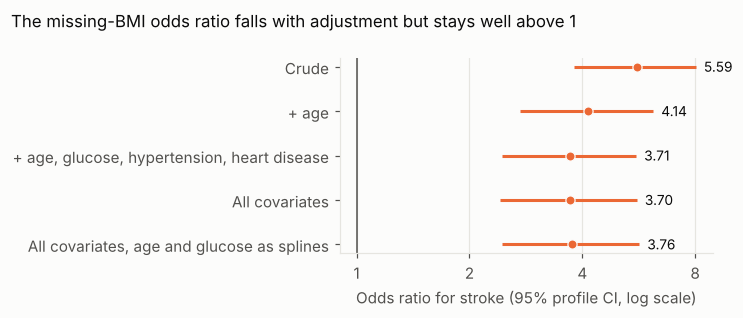

In [7]:
fig, ax = plt.subplots(figsize=(6.8, 2.9))
ys = np.arange(len(adj))[::-1]
ax.hlines(ys, adj["profile_low"], adj["profile_high"], color=MISSING, lw=2)
ax.plot(adj["OR"], ys, "o", ms=6, color=MISSING, mec=SURFACE, mew=0.8, ls="none", zorder=3)
for y, (_, row) in zip(ys, adj.iterrows()):
    ax.text(row["profile_high"] * 1.05, y, f"{row['OR']:.2f}", va="center", fontsize=9)
ax.axvline(1, color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
ax.minorticks_off()
ax.set_yticks(ys, adj["model"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio for stroke (95% profile CI, log scale)")
fig.suptitle("The missing-BMI odds ratio falls with adjustment but stays well above 1", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "missing_bmi_or_by_adjustment.png")
plt.show()

**Result: the excess shrinks but does not go away.**

| Model | OR for BMI missing (95% profile CI) |
|---|---|
| Crude | 5.59 (3.81 to 8.04) |
| + age | 4.14 (2.73 to 6.19) |
| + age, glucose, hypertension, heart disease | 3.71 (2.44 to 5.57) |
| All covariates | 3.70 (2.41 to 5.59) |
| All covariates, splines for age and glucose | 3.76 (2.45 to 5.68) |

All five likelihood-ratio p-values are below 0.001. Age accounts for most of the drop. Adding the remaining covariates changes little, and treating age and glucose flexibly does not change the conclusion. Profile and Wald intervals agree closely.

Stroke is common enough among these patients that an odds ratio overstates a risk ratio, so 3.7 should not be read as "3.7 times the risk". The next section gives an estimate on the scale of observed and expected strokes.

Unknown smoking status has an adjusted odds ratio for stroke of 1.00 (Wald 95% CI 0.68 to 1.50). Its low crude rate in `01_eda.ipynb` does not persist after adjustment.

## How much of the excess do the covariates explain?

A stroke model is fitted only on patients with BMI recorded and then applied to the 201 BMI-missing patients. This gives the number of strokes we would expect if they had the same risk as recorded-BMI patients with the same covariates.

The interval on expected strokes reflects coefficient uncertainty (`N_BOOT` draws from the estimated coefficient distribution). The interval on observed/expected is an exact Poisson interval that treats the expected count as fixed. The stroke rates by age band below use Wilson intervals.

In [8]:
def observed_vs_expected(formula, label):
    """Fit stroke risk on BMI-recorded patients, then predict the BMI-missing patients."""
    rec_md, mis_md = md[md["bmi_missing"] == 0], md[md["bmi_missing"] == 1]
    y_rec, X_rec = patsy.dmatrices(formula, rec_md, return_type="dataframe")
    fit = sm.Logit(y_rec.iloc[:, 0], X_rec).fit(disp=0)
    X_new = patsy.build_design_matrices([X_rec.design_info], mis_md, return_type="dataframe")[0]
    E = fit.predict(X_new).sum()
    draws = rng.multivariate_normal(fit.params.to_numpy(), fit.cov_params().to_numpy(), size=N_BOOT)
    E_draws = (1 / (1 + np.exp(-X_new.to_numpy() @ draws.T))).sum(axis=0)
    O, n = int(mis_md["stroke"].sum()), len(mis_md)
    return {"model": label, "n_missing": n, "observed": O, "expected": E,
            "expected_low": np.quantile(E_draws, ALPHA / 2), "expected_high": np.quantile(E_draws, 1 - ALPHA / 2),
            "observed_rate_pct": 100 * O / n, "expected_rate_pct": 100 * E / n,
            "obs_over_exp": O / E,
            "oe_low": stats.chi2.ppf(ALPHA / 2, 2 * O) / 2 / E,
            "oe_high": stats.chi2.ppf(1 - ALPHA / 2, 2 * (O + 1)) / 2 / E}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    oe = pd.DataFrame([
        observed_vs_expected(f"stroke ~ {COVARS}", "All covariates"),
        observed_vs_expected(f"stroke ~ {SPLINE}", "All covariates, splines"),
    ])
oe.to_csv(TABLES / "missing_bmi_observed_vs_expected.csv", index=False)
display(oe.round(3))

,model,n_missing,observed,expected,expected_low,expected_high,observed_rate_pct,expected_rate_pct,obs_over_exp,oe_low,oe_high
0,All covariates,201,40,15.519,13.689,18.413,19.9,7.721,2.577,1.841,3.510
1,"All covariates, splines",201,40,15.247,13.480,19.389,19.9,7.586,2.623,1.874,3.572


,age_band,bmi,n,strokes,rate_pct,ci_low_pct,ci_high_pct
0,<45,Recorded,2465,8,0.3,0.2,0.6
1,<45,Missing,68,2,2.9,0.8,10.1
2,45-64,Recorded,1491,68,4.6,3.6,5.7
3,45-64,Missing,59,12,20.3,12.0,32.3
4,65-74,Recorded,474,50,10.5,8.1,13.6
5,65-74,Missing,35,7,20.0,10.0,35.9
6,75+,Recorded,479,83,17.3,14.2,21.0
7,75+,Missing,39,19,48.7,33.9,63.8


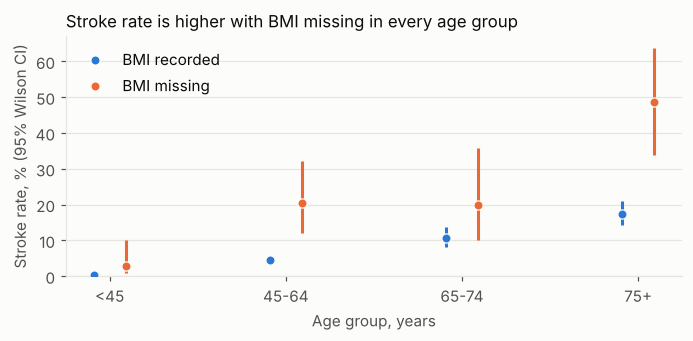

In [9]:
bands = pd.cut(df["age"], [0, 45, 65, 75, 83], right=False, labels=["<45", "45-64", "65-74", "75+"])
rows = []
for band in bands.cat.categories:
    for status, label in [(0, "Recorded"), (1, "Missing")]:
        sub = df[(bands == band) & (df["bmi_missing"] == status)]
        k, n = int(sub["stroke"].sum()), len(sub)
        lo, hi = proportion_confint(k, n, alpha=ALPHA, method="wilson")
        rows.append({"age_band": band, "bmi": label, "n": n, "strokes": k, "rate_pct": 100 * k / n,
                     "ci_low_pct": 100 * lo, "ci_high_pct": 100 * hi})
by_age = pd.DataFrame(rows)
by_age.to_csv(TABLES / "missing_bmi_stroke_rate_by_age.csv", index=False)
display(by_age.round(1))

fig, ax = plt.subplots(figsize=(6.4, 3.2))
offset = {"Recorded": -0.09, "Missing": 0.09}
color = {"Recorded": RECORDED, "Missing": MISSING}
xs = {b: i for i, b in enumerate(bands.cat.categories)}
for lab, g_ in by_age.groupby("bmi", sort=False):
    x = [xs[b] + offset[lab] for b in g_["age_band"]]
    ax.vlines(x, g_["ci_low_pct"], g_["ci_high_pct"], color=color[lab], lw=2)
    ax.plot(x, g_["rate_pct"], "o", ms=6, color=color[lab], mec=SURFACE, mew=0.8, label=f"BMI {lab.lower()}", ls="none", zorder=3)
ax.set_xticks(list(xs.values()), list(xs.keys()))
ax.grid(axis="x", visible=False)
ax.set_ylim(bottom=0)
ax.set_xlabel("Age group, years")
ax.set_ylabel("Stroke rate, % (95% Wilson CI)")
ax.set_title("Stroke rate is higher with BMI missing in every age group")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "missing_bmi_stroke_rate_by_age.png")
plt.show()

**Result: the covariates explain only part of the excess.** The model expects 15.5 strokes (95% CI 13.7 to 18.4) among the 201 missing-BMI patients, an expected rate of 7.7%. There were 40, a rate of 19.9%. Observed strokes are 2.58 times the expected number (95% CI 1.84 to 3.51). The spline version gives the same picture: 15.2 expected, ratio 2.62 (1.87 to 3.57).

So older age and worse health raise the expected rate from 4.3% to about 7.7%, but the observed rate is 19.9%. This estimate assumes the risk model from recorded-BMI patients applies to the missing-BMI patients.

**Reading the figure.** The stroke rate is higher with BMI missing in every age group: 2.9% against 0.3% under 45, 20.3% against 4.6% at 45 to 64, 20.0% against 10.5% at 65 to 74, and 48.7% against 17.3% at 75 and over. Age alone therefore cannot explain the gap. Groups are small (35 to 68 patients) and the intervals are wide. At 65 to 74 the two intervals overlap.

## D4. Can imputation recover the signal, and should the referral model use a missing-BMI indicator?

This section uses Track 3's pipeline from `src/modeling.py` (`oof_predictions`), with the same seed, so the numbers match `06_model.ipynb`. Two models are compared, both with BMI imputed m times inside each training fold and with no outcome in the imputer:

- **MI:** the referral model (age, gender, heart disease, hypertension, glucose, BMI, smoking).
- **MI + indicator:** the same model plus a 0/1 column for "BMI missing".

Predictions are out of fold. The AUC difference uses the paired stratified bootstrap from `src/modeling.py` (`N_BOOT` resamples). It resamples patients but does not refit the models.

Two questions:

1. **Does imputation recover the signal?** If it did, the MI model would predict close to the observed 19.9% stroke rate for the missing-BMI patients.
2. **What does the indicator add, and where does the gain come from?**

In [10]:
from src.modeling import (MODEL_COLS, UNITS, boot_metrics, design, fast_auc, fit_sm_logit,
                          impute_full, oof_predictions, prepare, rubin_pool)

model_df = prepare(load_raw())   # n = 5,109 (gender "Other" excluded, as in 06_model)
oof = oof_predictions(model_df, models=("mi", "mi_indicator"))
y_oof = oof["stroke"].to_numpy()
is_missing = model_df["bmi"].isna().to_numpy()

MODELS = {"mi": "MI", "mi_indicator": "MI + indicator"}

# Observed vs predicted stroke rate in each BMI group
rows = []
for group, mask in [("BMI recorded", ~is_missing), ("BMI missing", is_missing)]:
    n, observed = int(mask.sum()), int(y_oof[mask].sum())
    lo, hi = proportion_confint(observed, n, alpha=ALPHA, method="wilson")
    for key, label in MODELS.items():
        expected = oof.loc[mask, f"p_{key}"].sum()
        rows.append({"group": group, "model": label, "n": n, "observed": observed,
                     "observed_rate_pct": 100 * observed / n,
                     "observed_low_pct": 100 * lo, "observed_high_pct": 100 * hi,
                     "expected": expected, "predicted_rate_pct": 100 * expected / n,
                     "obs_over_exp": observed / expected,
                     # exact Poisson interval, treating the expected count as fixed
                     "oe_low": stats.chi2.ppf(ALPHA / 2, 2 * observed) / 2 / expected,
                     "oe_high": stats.chi2.ppf(1 - ALPHA / 2, 2 * (observed + 1)) / 2 / expected})
calib_groups = pd.DataFrame(rows)
calib_groups.to_csv(TABLES / "missing_bmi_indicator_calibration_by_group.csv", index=False)
display(calib_groups.round(3))

,group,model,n,observed,observed_rate_pct,observed_low_pct,observed_high_pct,expected,predicted_rate_pct,obs_over_exp,oe_low,oe_high
0,BMI recorded,MI,4908,209,4.258,3.728,4.860,231.913,4.725,0.901,0.783,1.032
1,BMI recorded,MI + indicator,4908,209,4.258,3.728,4.860,209.062,4.260,1.000,0.869,1.145
2,BMI missing,MI,201,40,19.900,14.968,25.961,17.155,8.535,2.332,1.666,3.175
3,BMI missing,MI + indicator,201,40,19.900,14.968,25.961,40.334,20.067,0.992,0.709,1.350


In [11]:
# AUC overall and within each BMI group, plus the paired bootstrap difference
auc_rows = []
for key, label in MODELS.items():
    p = oof[f"p_{key}"].to_numpy()
    auc_rows.append({"model": label,
                     "auc_all": fast_auc(y_oof, p),
                     "auc_bmi_recorded": fast_auc(y_oof[~is_missing], p[~is_missing]),
                     "auc_bmi_missing": fast_auc(y_oof[is_missing], p[is_missing])})
auc_table = pd.DataFrame(auc_rows)

boots = boot_metrics(y_oof, {k: oof[f"p_{k}"].to_numpy() for k in MODELS}, B=N_BOOT, seed=SEED)
diff = boots[("mi_indicator", "auc")] - boots[("mi", "auc")]
diff_low, diff_high = np.quantile(diff, [ALPHA / 2, 1 - ALPHA / 2])
auc_table["auc_diff_vs_mi"] = [0.0, auc_table["auc_all"][1] - auc_table["auc_all"][0]]
auc_table["diff_low"] = [np.nan, diff_low]
auc_table["diff_high"] = [np.nan, diff_high]
auc_table.to_csv(TABLES / "missing_bmi_indicator_auc.csv", index=False)
display(auc_table.round(4))

,model,auc_all,auc_bmi_recorded,auc_bmi_missing,auc_diff_vs_mi,diff_low,diff_high
0,MI,0.8388,0.8436,0.7179,0.00,NaN,NaN
1,MI + indicator,0.8488,0.8427,0.7149,0.01,0.0036,0.0166


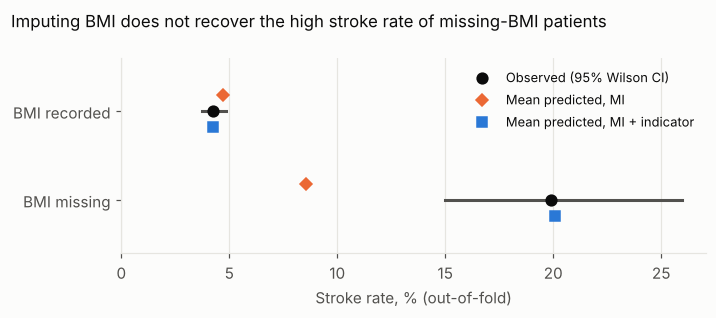

In [12]:
fig, ax = plt.subplots(figsize=(6.6, 2.9))
ypos = {"BMI recorded": 1, "BMI missing": 0}
for group, g_ in calib_groups.groupby("group", sort=False):
    y0 = ypos[group]
    first = g_.iloc[0]
    ax.plot([first.observed_low_pct, first.observed_high_pct], [y0, y0], color=INK_2, lw=2)
    ax.plot(first.observed_rate_pct, y0, "o", ms=7, color=INK, label="Observed (95% Wilson CI)" if y0 == 0 else None)
    for _, row in g_.iterrows():
        is_mi = row.model == "MI"
        ax.plot(row.predicted_rate_pct, y0 + (0.18 if is_mi else -0.18), "D" if is_mi else "s", ms=6,
                color=MISSING if is_mi else RECORDED, ls="none",
                label=(f"Mean predicted, {row.model}" if y0 == 0 else None))
ax.set_yticks([1, 0], ["BMI recorded", "BMI missing"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(left=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Stroke rate, % (out-of-fold)")
ax.legend(loc="upper right", fontsize=8.5)
fig.suptitle("Imputing BMI does not recover the high stroke rate of missing-BMI patients", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "missing_bmi_indicator_calibration.png")
plt.show()

**Result: imputation does not recover the signal.** For the 201 missing-BMI patients the MI model predicts a mean stroke risk of 8.5%, which is 17.2 expected strokes against 40 observed (observed/expected 2.33, 95% CI 1.67 to 3.18). Imputed BMI values are ordinary BMIs drawn from the recorded-BMI distribution given the covariates (see `06_model.ipynb`, imputation check), and BMI itself has an odds ratio close to 1 in the referral model. So filling in BMI cannot carry the extra risk. The extra risk lives in the fact that BMI is missing, not in the BMI value. The MI model also slightly over-predicts for recorded-BMI patients (observed/expected 0.90, 0.78 to 1.03), because the missing-BMI excess is spread across everyone through the intercept.

**Result: the indicator's gain comes only from separating the two groups.** Adding the indicator raises the out-of-fold AUC from 0.839 to 0.849 (paired difference +0.010, 95% CI 0.004 to 0.017), the same figure as in `06_model.ipynb`. Within each group it does not help: the AUC is 0.844 without and 0.843 with the indicator among recorded-BMI patients, and 0.718 against 0.715 among missing-BMI patients. The indicator does not rank patients better. It moves the 201 missing-BMI patients up as one block, and its predictions match the observed rate in both groups (observed/expected 0.99 and 1.00).

### Why the referral model has no missing-BMI indicator

We leave the indicator out of the referral model even though it improves the AUC by 0.010 (95% CI 0.004 to 0.017). The gain is real in this dataset, but it does not come from better ranking of patients: within the recorded-BMI and missing-BMI groups the AUC is unchanged. It comes only from flagging the 201 patients whose BMI is missing, whose stroke rate is 19.9%. Section D2 showed that this excess is not explained by age, glucose, hypertension, heart disease or the other recorded covariates (adjusted OR 3.7). The most plausible explanations are that BMI was not recorded because of the stroke (for example, an acute patient who could not be weighed) or that these records came from a different source. Both are features of how this dataset was collected. In the intended setting, a primary-care physician sees patients before any stroke and can measure BMI, so a missing value would not mean the same thing, and the model would add a 3.7-fold odds increase for a recording pattern that does not exist there. An indicator would also reward missing data: a patient who was not weighed would get a higher referral score than an identical patient who was. Sperrin et al. (2020) make the same point: a missing indicator helps prediction only when the missingness pattern is the same where the model is used. Leaving it out has a cost that we report: the model under-predicts for the missing-BMI patients in this dataset (8.5% predicted against 19.9% observed) and over-predicts slightly for the others (observed/expected 0.90). If BMI is always measured in practice, the recorded-BMI group is the closer match to clinic patients, so the slight over-prediction is the more relevant of the two for the threshold analysis.

## D3. Delta-adjustment sensitivity analysis (MNAR)

The MAR assumption cannot be tested from the observed data (see the interpretation at the end). Delta adjustment asks how far the results move if missing BMIs are systematically different from what MAR imputation gives. Each imputed BMI for the 201 missing-BMI patients is shifted by δ kg/m², for δ from −5 to +5, and the referral model is refitted on each of the m imputed datasets and pooled with Rubin's rules (van Buuren, 2018, section 9.2).

This uses the inference set-up from `src/modeling.py` (`impute_full`: imputer fitted on the full data with stroke in the imputation model), the same set-up that gives the odds ratios in `06_model.ipynb`. A shift of 5 kg/m² is about 0.6 standard deviations of recorded BMI (SD 7.9) applied to every missing patient at once, so it is a large departure from MAR.

Reported for each δ: the BMI odds ratio per 5 kg/m², the age odds ratio as a check that other estimates are stable, and the mean predicted stroke risk for the 201 missing-BMI patients.

In [13]:
X_full = design(model_df)
y_full = model_df["stroke"].to_numpy()
imputed_sets = impute_full(model_df, m=N_IMPUTATIONS, seed=SEED)
TERM_NAMES = ["const"] + MODEL_COLS

delta_rows = []
for delta in range(-5, 6):
    estimates, variances, missing_risk = [], [], []
    for X_imp in imputed_sets:
        X_shift = X_imp.copy()
        X_shift.loc[is_missing, "bmi"] += delta / UNITS["bmi"]   # BMI is stored per 5 kg/m²
        fit = fit_sm_logit(X_shift, y_full)
        estimates.append(fit.params.to_numpy())
        variances.append(np.diag(fit.cov_params().to_numpy()))
        risk = fit.predict(sm.add_constant(X_shift[MODEL_COLS], has_constant="add"))
        missing_risk.append(risk[is_missing].mean())
    pooled = rubin_pool(np.array(estimates), np.array(variances))
    pooled.index = TERM_NAMES
    delta_rows.append({"delta_kg_m2": delta,
                       "bmi_or": np.exp(pooled.loc["bmi", "estimate"]),
                       "bmi_ci_low": np.exp(pooled.loc["bmi", "ci_low"]),
                       "bmi_ci_high": np.exp(pooled.loc["bmi", "ci_high"]),
                       "bmi_p": pooled.loc["bmi", "p_value"],
                       "age_or": np.exp(pooled.loc["age", "estimate"]),
                       "age_ci_low": np.exp(pooled.loc["age", "ci_low"]),
                       "age_ci_high": np.exp(pooled.loc["age", "ci_high"]),
                       "mean_risk_missing_pct": 100 * np.mean(missing_risk)})
delta_table = pd.DataFrame(delta_rows)
delta_table.to_csv(TABLES / "missing_bmi_delta_adjustment.csv", index=False)
display(delta_table.round(3))

,delta_kg_m2,bmi_or,bmi_ci_low,bmi_ci_high,bmi_p,age_or,age_ci_low,age_ci_high,mean_risk_missing_pct
0,-5,0.925,0.826,1.036,0.178,1.985,1.792,2.198,8.891
1,-4,0.937,0.837,1.050,0.262,1.988,1.795,2.202,8.738
2,-3,0.950,0.849,1.064,0.373,1.991,1.797,2.207,8.621
3,-2,0.963,0.861,1.078,0.509,1.995,1.800,2.211,8.540
4,-1,0.976,0.873,1.091,0.670,1.998,1.802,2.216,8.494
5,0,0.989,0.885,1.105,0.848,2.002,1.805,2.221,8.483
6,1,1.002,0.898,1.119,0.966,2.006,1.808,2.225,8.506
7,2,1.015,0.911,1.132,0.783,2.010,1.811,2.230,8.562
8,3,1.028,0.923,1.144,0.613,2.014,1.814,2.235,8.650
9,4,1.040,0.936,1.157,0.463,2.017,1.817,2.240,8.767


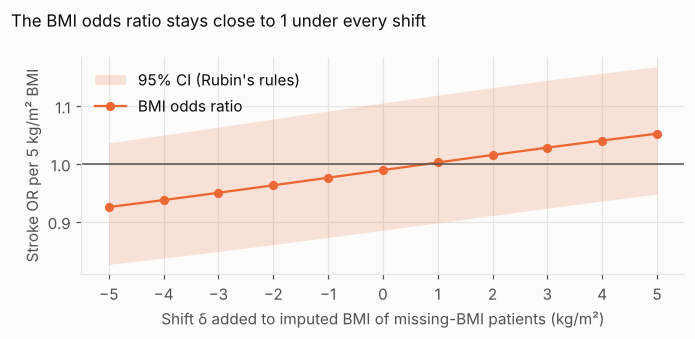

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 3.1))
ax.fill_between(delta_table["delta_kg_m2"], delta_table["bmi_ci_low"], delta_table["bmi_ci_high"],
                color=MISSING, alpha=0.18, lw=0, label="95% CI (Rubin's rules)")
ax.plot(delta_table["delta_kg_m2"], delta_table["bmi_or"], "o-", color=MISSING, ms=5, label="BMI odds ratio")
ax.axhline(1, color=INK_2, lw=1)
ax.set_xticks(delta_table["delta_kg_m2"])
ax.set_xlabel("Shift δ added to imputed BMI of missing-BMI patients (kg/m²)")
ax.set_ylabel("Stroke OR per 5 kg/m² BMI")
ax.legend(loc="upper left")
fig.suptitle("The BMI odds ratio stays close to 1 under every shift", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "missing_bmi_delta_adjustment.png")
plt.show()

**Result: the conclusions do not depend on the MAR assumption, within ±5 kg/m².**

- The BMI odds ratio per 5 kg/m² moves from 0.93 (95% CI 0.83 to 1.04) at δ = −5 to 1.05 (0.95 to 1.17) at δ = +5. At δ = 0 it is 0.99 (0.89 to 1.11), the value in `06_model.ipynb`. Every interval includes 1, so under any of these shifts the data are consistent with BMI having little association with stroke once the other factors are in the model.
- The age odds ratio stays between 1.98 and 2.02 per 10 years, so other estimates are not affected.
- Mean predicted risk for the missing-BMI patients stays between 8.5% and 8.9%, far below the observed 19.9%. No plausible BMI value explains the excess: it would need BMI to have a strong effect on stroke, and it does not.

For the referral decision this means MNAR in BMI is unlikely to matter. Predictions for the 201 missing-BMI patients change by less than half a percentage point across the range, so the recommended threshold (Track 5) should not move. That last point is an expectation from these numbers, not a re-run of the threshold analysis.

The shift is applied to all missing patients equally. A shift that differs between stroke and non-stroke patients would be a different (and stronger) MNAR scenario, which is not tested here.

## Interpretation: MCAR, MAR, MNAR and reverse causation

**What the data establish**

1. BMI is not missing completely at random. Missingness is related to age, glucose, hypertension, heart disease and smoking.
2. Those differences explain only part of the excess. After adjustment the odds ratio is about 3.7, and strokes are about 2.6 times the covariate-expected number.
3. So missingness is associated with stroke beyond what the recorded covariates explain.

**What the data cannot establish**

The dataset does not say when BMI was measured relative to the stroke, or which clinical source each record came from. Two explanations remain open and cannot be separated here:

- **Reverse causation or care pathway.** BMI may go unrecorded because of the stroke, for example when an acute patient cannot be weighed. The persistent excess is what this explanation predicts, but it does not prove it.
- **Different data source.** Records without BMI may come from a site or form with a higher stroke prevalence.

**MAR or MNAR**

A persistent adjusted odds ratio does not on its own show MNAR. Stroke is an observed variable, so missingness that depends on stroke is still MAR, provided the imputation model conditions on stroke. The MNAR question is whether missingness depends on the unobserved BMI value itself, after conditioning on the covariates and stroke. Observed data cannot test that, so it was handled by sensitivity analysis (D3, delta adjustment): shifting the imputed BMIs by up to ±5 kg/m² leaves the BMI odds ratio close to 1 and does not change the conclusions.

This refines the wording in KB 04, which reads a persistent odds ratio as pointing to MNAR or a data-collection artefact. An artefact remains possible, and it matters for the referral model. MNAR specifically is not shown by this analysis.

**What this means for imputation**

- *For inference (odds ratios).* Multiple imputation with `stroke` in the imputation model is valid if missingness depends only on observed variables, including stroke. That assumption is plausible but untestable.
- *For prediction.* Test patients' strokes are unknown in real use, so the imputer cannot use them. Imputed BMI for these patients then reflects their covariates, and it cannot carry the excess risk that remains after accounting for those covariates. D4 confirms this: with imputed BMI the model predicts 8.5% for these patients against 19.9% observed.
- *For the referral model.* A missing-BMI indicator would capture this excess, but if BMI is missing because of the stroke, that signal would not exist in a primary-care clinic where BMI is measured beforehand. This supports leaving the indicator out, as argued in D4, even though it would raise the AUC by 0.010.